# Clasificación multietiqueta de anomalías de rodilla en RM (CNN + supervisión débil)

Examen parcial, **Pregunta 1**. Datos: competencia de Kaggle *RSNA Knee Abnormality Detection*.
Para cada estudio de RM se predicen 12 hallazgos (`ACL, MCL, Medial Meniscus, Lateral Meniscus,
Medial OA, Lateral OA, PF OA, Effusion, Synovitis, Baker's, Contusion, Fracture`).
Solo 58 estudios traen etiqueta experta (*gold*); el resto solo trae el reporte en texto libre (~12 idiomas).

| Entregable de la Pregunta 1 | Sección |
|---|---|
| 1. Pipeline propio de etiquetas débiles + acuerdo/ruido vs gold | §3 |
| 2. Dos arquitecturas: CNN 2.5D desde cero y *transfer learning* ImageNet, 12 sigmoides | §5, §6 |
| 3. AUC macro + por hallazgo en gold; precisión/recall/F1 con umbral justificado | §7 |
| 4. Ablaciones: pérdida (BCE vs focal), etiquetas ruidosas (ponderar vs solo confiables), plano, profundidad | §6, §7 |
| 5. Grad-CAM para ≥3 hallazgos | §8 |
| 6. Prevalencia + mitigación del desbalance (`pos_weight`, focal) evaluada | §4, §7 |
| 7. Sesgo geográfico/lingüístico: calidad de extracción por idioma | §3 (tabla por idioma) |

**Modos** (variable `MODE` en la celda siguiente):

| MODE | Dónde | Qué hace |
|---|---|---|
| `synthetic` | local o Kaggle (CPU) | genera DICOM y reportes falsos con el esquema real y corre todo |
| `preprocess` | Kaggle, CPU, Internet ON | DICOM → caché `uint8` (`train_vols.npy`) |
| `labels` | Kaggle, CPU | solo extracción de etiquetas + validación (para iterar el léxico rápido) |
| `train` | Kaggle, GPU, Internet ON | etiquetas + todos los experimentos + métricas + Grad-CAM |
| `infer` | Kaggle, GPU, Internet OFF | opcional: `submission.csv` con el mejor modelo |

In [1]:
MODE = 'train'   # 'synthetic' | 'preprocess' | 'labels' | 'train' | 'infer'
LIMIT = 0            # preprocess: >0 procesa solo N estudios (prueba rápida). Volver a 0 antes de "Save Version"
SUBSET = 600         # estudios de entrenamiento (+ holdout) muestreados de forma estratificada (enunciado: 300–600)
RUN = None           # None = todos los experimentos de §6; o una lista, p. ej. ['A_scratch', 'B_resnet18']
SEEDS = [42, 1, 2]   # cada experimento se repite con estas semillas; la primera alimenta tablas, figuras y Grad-CAM

# Decodificadores JPEG Lossless / JPEG 2000 para pydicom (Kaggle solo trae Pillow, que no los lee).
# Con internet se instalan de PyPI; sin internet (modo infer) desde la carpeta wheels/ que deja knee-train.
import glob, os, subprocess, sys
PKGS = ['pylibjpeg', 'pylibjpeg-libjpeg', 'pylibjpeg-openjpeg']
def pip(*args):
    # --no-deps: su única dependencia es numpy (ya instalado); así pip nunca cambia lo que usa torch.
    r = subprocess.run([sys.executable, '-m', 'pip', *args, '--no-deps', '-q', '--retries', '0', '--timeout', '15'],
                       capture_output=True, text=True)
    if r.returncode:
        print(f'pip {args[0]} falló:', r.stderr.strip()[-600:])
    return r.returncode == 0
WHEELS = sorted(glob.glob('/kaggle/input/*/wheels') + glob.glob('/kaggle/input/*/*/*/wheels'))
JPEG_OK = pip('install', '--no-index', '--find-links', WHEELS[0], *PKGS) if WHEELS else pip('install', *PKGS)
if JPEG_OK and MODE == 'train' and os.path.isdir('/kaggle/working') and not WHEELS:
    pip('download', *PKGS, '-d', '/kaggle/working/wheels')   # viaja con kneenet.pt hacia knee-submit
print('decodificadores JPEG (pylibjpeg):', 'instalados' if JPEG_OK else
      'NO instalados: activa Internet, o en modo infer agrega knee-train como Input')

import math, time, random, re, unicodedata
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, f1_score, precision_recall_fscore_support
import pydicom

LABELS = ['ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA',
          'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']
PLANES = ['Sagittal', 'Coronal', 'Axial']
SYN = MODE == 'synthetic'
CFG = dict(
    img=64 if SYN else 224,      # lado de cada corte en la caché
    depth=8 if SYN else 16,      # cortes muestreados por serie
    k=4 if SYN else 8,           # ventanas 2.5D por serie en entrenamiento (en evaluación: todas)
    d_model=64 if SYN else 256,  # ancho de la cabeza de atención
    epochs=3 if SYN else 15,   # la época se elige por AUC en holdout: épocas de más no empeoran el modelo guardado
    bs=4 if SYN else 8,
    lr_bb=1e-4, lr_head=1e-3, wd=1e-2, warmup=0.05,
    workers=0 if SYN else 4,
    # valores por defecto de cada experimento (§6 los sobrescribe)
    backbone='resnet18', loss='bce', labels='weighted', planes=[0, 1, 2], pos_weight=True,
)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
INPUT = './work/input' if SYN else '/kaggle/input'
WORK = './work' if SYN else '/kaggle/working'
os.makedirs(WORK, exist_ok=True)
random.seed(42); np.random.seed(42); torch.manual_seed(42)
print(MODE, DEVICE, CFG)


def find_file(pattern, root=INPUT, max_depth=4):
    """Busca por niveles: os.walk sobre los 820k DICOM de la competencia tardaría minutos."""
    for depth in range(max_depth + 1):
        hits = sorted(glob.glob(os.path.join(root, *['*'] * depth, pattern)))
        if hits:
            return hits
    return []


def find_dir(fname, root=INPUT):
    hits = find_file(fname, root)
    if not hits:
        seen = sorted(glob.glob(os.path.join(root, '*'))) + sorted(glob.glob(os.path.join(root, '*', '*')))[:30]
        raise FileNotFoundError(f'{fname} no está bajo {root}: adjunta el dataset correspondiente.\n'
                                f'Contenido actual de {root}:\n  ' + ('\n  '.join(seen) or '(vacío: no hay ningún Input)'))
    return os.path.dirname(hits[0])

decodificadores JPEG (pylibjpeg): instalados
train cuda {'img': 224, 'depth': 16, 'k': 8, 'd_model': 256, 'epochs': 15, 'bs': 8, 'lr_bb': 0.0001, 'lr_head': 0.001, 'wd': 0.01, 'warmup': 0.05, 'workers': 4, 'backbone': 'resnet18', 'loss': 'bce', 'labels': 'weighted', 'planes': [0, 1, 2], 'pos_weight': True}


## 0. Datos sintéticos (solo `MODE='synthetic'`)
Replica el esquema real: `train.csv` (con `Report` y 12 etiquetas, NaN salvo en los *gold*),
`train_series.csv`, `train_series/<Study>/<Series>/<SOP>.dcm`, `test.csv`, `test_series.csv`, `sample_submission.csv`.
Los reportes se escriben en inglés, español, alemán o francés: un hallazgo positivo se afirma (a veces con duda),
uno negativo a veces se niega y a veces no se menciona, y algunos positivos se omiten (ruido realista).
En la imagen, cada hallazgo positivo dibuja un disco brillante en una posición propia.

In [2]:
SYN_TERMS = {
    'en': ['anterior cruciate ligament tear', 'medial collateral ligament sprain', 'tear of the medial meniscus',
           'tear of the lateral meniscus', 'osteoarthritis of the medial compartment',
           'osteoarthritis of the lateral compartment', 'patellofemoral osteoarthritis', 'joint effusion',
           'synovitis', 'Baker cyst', 'bone contusion', 'fracture'],
    'es': ['rotura del ligamento cruzado anterior', 'esguince del ligamento colateral medial', 'rotura del menisco interno',
           'rotura del menisco externo', 'artrosis del compartimento medial', 'artrosis del compartimento lateral',
           'artrosis patelofemoral', 'derrame articular', 'sinovitis', 'quiste de Baker', 'contusión ósea', 'fractura'],
    'de': ['Ruptur des vorderen Kreuzbandes', 'Zerrung des Innenbandes', 'Innenmeniskusriss', 'Außenmeniskusriss',
           'mediale Gonarthrose', 'laterale Gonarthrose', 'Retropatellararthrose', 'Gelenkerguss', 'Synovitis',
           'Bakerzyste', 'Knochenkontusion', 'Fraktur'],
    'fr': ['rupture du ligament croisé antérieur', 'entorse du ligament collatéral médial', 'déchirure du ménisque interne',
           'déchirure du ménisque externe', 'arthrose fémoro-tibiale interne', 'arthrose fémoro-tibiale externe',
           'arthrose fémoro-patellaire', 'épanchement articulaire', 'synovite', 'kyste poplité', 'contusion osseuse',
           'fracture'],
}
SYN_POS = {'en': '{t} is seen.', 'es': 'Se observa {t}.', 'de': 'Nachweis einer {t}.', 'fr': 'On note une {t}.'}
SYN_HEDGE = {'en': 'Possible {t}.', 'es': 'Posible {t}.', 'de': 'Verdacht auf {t}.', 'fr': 'Suspicion de {t}.'}
SYN_NEG = {'en': 'No {t}.', 'es': 'No se observa {t}.', 'de': 'Kein Hinweis auf {t}.', 'fr': 'Pas de {t}.'}


def synthetic_report(y, rng):
    lang = rng.choice(list(SYN_TERMS))
    out = []
    for j, t in enumerate(SYN_TERMS[lang]):
        u = rng.random()
        if y[j] and u < 0.1:
            continue                                   # positivo omitido en el reporte
        if y[j]:
            out.append((SYN_HEDGE if u < 0.2 else SYN_POS)[lang].format(t=t))
        elif u < 0.6:
            out.append(SYN_NEG[lang].format(t=t))
    rng.shuffle(out)
    return ' '.join(out)


def write_dicom(path, img, pos, inst):
    from pydicom.dataset import Dataset as DcmDS, FileMetaDataset
    from pydicom.uid import ExplicitVRLittleEndian, generate_uid
    meta = FileMetaDataset()
    meta.MediaStorageSOPClassUID = '1.2.840.10008.5.1.4.1.1.4'
    meta.MediaStorageSOPInstanceUID = generate_uid()
    meta.TransferSyntaxUID = ExplicitVRLittleEndian
    ds = DcmDS(); ds.file_meta = meta
    ds.SOPClassUID, ds.SOPInstanceUID = meta.MediaStorageSOPClassUID, meta.MediaStorageSOPInstanceUID
    ds.Modality, ds.InstanceNumber = 'MR', inst
    ds.ImageOrientationPatient = [1, 0, 0, 0, 1, 0]
    ds.ImagePositionPatient = [0, 0, float(pos)]
    ds.Rows, ds.Columns = img.shape
    ds.SamplesPerPixel, ds.PhotometricInterpretation = 1, 'MONOCHROME2'
    ds.BitsAllocated, ds.BitsStored, ds.HighBit, ds.PixelRepresentation = 16, 16, 15, 0
    ds.PixelData = img.astype(np.uint16).tobytes()
    ds.save_as(path, enforce_file_format=True)


def make_synthetic(root, n_train=56, n_test=6, n_gold=16, p=0.35):
    from pydicom.uid import generate_uid
    rng = np.random.default_rng(0)
    comp = os.path.join(root, 'rsna-knee-abnormality-detection'); os.makedirs(comp, exist_ok=True)
    rows, series_rows = {'train': [], 'test': []}, {'train': [], 'test': []}
    for split, n in [('train', n_train), ('test', n_test)]:
        for s in range(n):
            uid, y = generate_uid(), (rng.random(12) < p).astype(int)
            planes = [pl for pl in PLANES if rng.random() < 0.9] or ['Sagittal']  # a veces falta un plano
            for pl in planes:
                sid, n_sl, (H, W) = generate_uid(), int(rng.integers(10, 20)), (80, 96)
                sdir = os.path.join(comp, f'{split}_series', uid, sid); os.makedirs(sdir)
                order = rng.permutation(n_sl)
                for z in range(n_sl):
                    img = rng.normal(300, 60, (H, W))
                    for j in np.where(y)[0]:
                        if PLANES[j % 3] == pl and n_sl // 4 <= z <= 3 * n_sl // 4:
                            cy, cx = H / 2 + 22 * math.sin(2 * math.pi * j / 12), W / 2 + 22 * math.cos(2 * math.pi * j / 12)
                            yy, xx = np.ogrid[:H, :W]
                            img[(yy - cy) ** 2 + (xx - cx) ** 2 < 25] += 700
                    write_dicom(os.path.join(sdir, generate_uid() + '.dcm'), np.clip(img, 0, 4000), z * 3.0, int(order[z]) + 1)
                fluid = int(rng.random() < 0.6)
                series_rows[split].append(dict(StudyInstanceUID=uid, SeriesInstanceUID=sid, Fluid_Sensitive=fluid,
                                               Fat_Suppression=fluid, Anatomical_Plane=pl))
            row = dict(StudyInstanceUID=uid)
            if split == 'train':
                row['Report'] = synthetic_report(y, rng)
                row.update({l: (y[j] if s < n_gold else np.nan) for j, l in enumerate(LABELS)})
            rows[split].append(row)
    pd.DataFrame(rows['train']).to_csv(f'{comp}/train.csv', index=False)
    pd.DataFrame(rows['test']).to_csv(f'{comp}/test.csv', index=False)
    for split in ['train', 'test']:
        pd.DataFrame(series_rows[split]).to_csv(f'{comp}/{split}_series.csv', index=False)
    sub = pd.DataFrame(rows['test'])[['StudyInstanceUID']]; sub[LABELS] = 0.5
    sub.to_csv(f'{comp}/sample_submission.csv', index=False)


if SYN and not os.path.exists(f'{INPUT}/rsna-knee-abnormality-detection/train.csv'):
    make_synthetic(INPUT)

COMP = find_dir('train_series.csv')
print('Datos de la competencia en', COMP)

Datos de la competencia en /kaggle/input/competitions/rsna-knee-abnormality-detection


## 1. Exploración rápida
`train.csv` trae el reporte (`Report`) pero `test.csv` no: el texto solo sirve para **crear etiquetas**,
no como entrada del modelo. Cada serie viene descrita por plano + `Fluid_Sensitive` + `Fat_Suppression`.

In [3]:
train_df = pd.read_csv(f'{COMP}/train.csv')
train_df['Report'] = train_df['Report'].fillna('').astype(str)
train_series = pd.read_csv(f'{COMP}/train_series.csv')
gold_mask = train_df[LABELS].notna().all(axis=1)
print(f'estudios: {len(train_df)} | gold (etiqueta experta): {gold_mask.sum()} | series: {len(train_series)}')
print(train_series.groupby(['Anatomical_Plane', 'Fluid_Sensitive', 'Fat_Suppression']).size())
print('series por estudio:', train_series.groupby('StudyInstanceUID').size().describe()[['min', '50%', 'max']].to_dict())
print('prevalencia en gold:\n', train_df.loc[gold_mask, LABELS].mean().round(2).to_dict())

estudios: 4407 | gold (etiqueta experta): 58 | series: 24371
Anatomical_Plane  Fluid_Sensitive  Fat_Suppression
Axial             0                0                  1179
                  1                1                  4719
Coronal           0                0                  3985
                  1                1                  4624
Sagittal          0                0                  5197
                  1                1                  4667
dtype: int64
series por estudio: {'min': 3.0, '50%': 5.0, 'max': 14.0}
prevalencia en gold:
 {'ACL': 0.41, 'MCL': 0.16, 'Medial Meniscus': 0.45, 'Lateral Meniscus': 0.4, 'Medial OA': 0.26, 'Lateral OA': 0.19, 'PF OA': 0.36, 'Effusion': 0.6, 'Synovitis': 0.47, "Baker's": 0.21, 'Contusion': 0.33, 'Fracture': 0.31}


## 2. Preprocesamiento DICOM → volumen 2.5D
Por estudio guardamos un tensor `uint8` de forma `(3 planos, depth, img, img)` y una máscara de planos presentes.
- **Selección de serie**: por plano, la que es sensible a fluido + supresión grasa (muestra edema, derrame,
  desgarros); si falla al decodificar, la siguiente.
- **Orden de cortes**: el nombre del archivo es un UID sin orden. Se ordena por la proyección de
  `ImagePositionPatient` sobre la normal del plano (`ImageOrientationPatient`); `InstanceNumber` como respaldo.
- Solo se decodifican los `depth` cortes muestreados (los demás solo se leen como cabecera → mucho más rápido).
- **Intensidad**: la RM no tiene escala absoluta → normalizamos cada serie a sus percentiles 1–99.
- Recorte cuadrado central + redimensión con *antialias*.
- **Sin espejado horizontal en ninguna parte**: medial/lateral es información del diagnóstico.

In [4]:
def square_resize(a, img):
    h, w = a.shape; m = min(h, w)
    a = a[(h - m) // 2:(h - m) // 2 + m, (w - m) // 2:(w - m) // 2 + m]
    t = torch.from_numpy(np.ascontiguousarray(a, dtype=np.float32))[None, None]
    return F.interpolate(t, size=(img, img), mode='bilinear', antialias=True, align_corners=False)[0, 0].numpy()


def slice_pos(h):
    try:
        o = np.array(h.ImageOrientationPatient, float)
        return float(np.dot(np.array(h.ImagePositionPatient, float), np.cross(o[:3], o[3:])))
    except Exception:
        return float(getattr(h, 'InstanceNumber', 0) or 0)


def read_series(sdir, depth, img):
    hdrs = []
    for f in glob.glob(os.path.join(sdir, '*.dcm')):
        try:
            hdrs.append((slice_pos(pydicom.dcmread(f, stop_before_pixels=True)), f))
        except Exception:
            pass
    if not hdrs:
        return None
    hdrs.sort()
    vol = []
    for i in np.linspace(0, len(hdrs) - 1, depth).round().astype(int):
        try:
            ds = pydicom.dcmread(hdrs[i][1])
            a = ds.pixel_array.astype(np.float32)
            if a.ndim == 3:
                a = a[len(a) // 2]
            if ds.get('PhotometricInterpretation') == 'MONOCHROME1':
                a = a.max() - a
            vol.append(square_resize(a, img))
        except Exception:  # p. ej. JPEG 2000 sin decodificador instalado
            vol.append(None)
    ok = [v for v in vol if v is not None]
    if not ok:
        return None
    vol = np.stack([v if v is not None else np.zeros_like(ok[0]) for v in vol])
    lo, hi = np.percentile(vol, [1, 99])
    return np.clip((vol - lo) / (hi - lo + 1e-6) * 255, 0, 255).astype(np.uint8)


def load_study(root, uid, sdf):
    vol = np.zeros((3, CFG['depth'], CFG['img'], CFG['img']), np.uint8)
    mask = np.zeros(3, bool)
    for p, plane in enumerate(PLANES):
        cand = sdf[sdf.Anatomical_Plane == plane].sort_values(['Fluid_Sensitive', 'Fat_Suppression'], ascending=False)
        for sid in cand.SeriesInstanceUID:
            v = read_series(os.path.join(root, uid, sid), CFG['depth'], CFG['img'])
            if v is not None:
                vol[p], mask[p] = v, True
                break
    return vol, mask


EMPTY_SERIES = train_series.iloc[:0]


class DicomStudies(Dataset):
    """Lee estudios directo desde DICOM; se usa para crear la caché y en inferencia."""
    def __init__(self, split, ids, series):
        self.root, self.ids = os.path.join(COMP, f'{split}_series'), list(ids)
        self.groups = dict(tuple(series.groupby('StudyInstanceUID')))
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, i):
        torch.set_num_threads(1)
        return load_study(self.root, self.ids[i], self.groups.get(self.ids[i], EMPTY_SERIES))


def build_cache(split, ids, series, out):
    ds = DicomStudies(split, ids, series)
    vols = np.lib.format.open_memmap(f'{out}/{split}_vols.npy', 'w+', np.uint8,
                                     (len(ds), 3, CFG['depth'], CFG['img'], CFG['img']))
    masks = np.zeros((len(ds), 3), bool)
    dl = DataLoader(ds, batch_size=None, num_workers=CFG['workers'])   # paralelo, en orden
    t0 = time.time()
    for i, (v, m) in enumerate(dl):
        vols[i], masks[i] = v.numpy(), m.numpy()
        if i % 500 == 0:
            print(f'{i}/{len(ds)} estudios | {time.time() - t0:.0f}s')
    vols.flush()
    np.save(f'{out}/{split}_masks.npy', masks)
    np.save(f'{out}/{split}_ids.npy', np.array(ids))
    print('planos presentes (sag, cor, ax):', masks.mean(0).round(3), '| sin ningún plano:', (~masks.any(1)).sum())


def check_decoding(ids, series, split='train'):
    """Intenta decodificar 1 corte por serie y cuenta éxitos/fallas por tipo de compresión."""
    from collections import Counter
    res = Counter()
    for uid in ids:
        for sid in series.loc[series.StudyInstanceUID == uid, 'SeriesInstanceUID']:
            f = next(iter(glob.glob(os.path.join(COMP, f'{split}_series', uid, sid, '*.dcm'))), None)
            if f is None:
                continue
            ds = pydicom.dcmread(f)
            try:
                ds.pixel_array; ok = 'ok'
            except Exception:
                ok = 'FALLA'
            res[(ds.file_meta.TransferSyntaxUID.name, ok)] += 1
    out = pd.Series(res).unstack(fill_value=0)
    print(out)
    return int(out['FALLA'].sum()) if 'FALLA' in out else 0


if MODE in ('synthetic', 'preprocess'):
    print('decodificadores de pixel disponibles:',
          [h.__name__.split('.')[-1] for h in pydicom.config.pixel_data_handlers if h.is_available()]
          if hasattr(pydicom.config, 'pixel_data_handlers') else 'pydicom>=3 (pixels backend)')
    fallas = check_decoding(train_df.StudyInstanceUID[:LIMIT or 100], train_series)
    if fallas:
        print(f'⚠️ {fallas} series no se pudieron decodificar: revisa la línea "decodificadores JPEG" de la primera celda (¿Internet activado?)')
    build_cache('train', train_df.StudyInstanceUID.tolist()[:LIMIT or None], train_series, WORK)

## 3. Entregable 1: extracción propia de etiquetas débiles desde los reportes

Extractor **basado en reglas multilingües** (inglés, español, francés, alemán, neerlandés, turco,
croata/bosnio, búlgaro y griego), sin modelos externos:
1. **Normalización**: minúsculas, sin tildes (NFKD), `ß→ss`, `ı→i`. El léxico se normaliza igual.
2. **Cláusulas**: se corta en `.` `;` y saltos de línea (un encabezado `Fracturas:` se une a la línea siguiente).
3. **Menciones**: hallazgos de un término (derrame, sinovitis, quiste de Baker, contusión, fractura) o
   **anatomía + patología** a ≤60 caracteres (p. ej. *menisco interno* + *rotura*; también compuestos
   alemanes como *Innenmeniskusriss*). Anatomía + término de normalidad (*intacto*, *unauffällig*) = negativo explícito.
4. **Contexto** (estilo NegEx): negación antes (*no, sin, kein, geen, без, χωρίς…*) o después
   (*intacto, yok, izlenmedi…*) → 0; duda (*posible, Verdacht, πιθανή, ?…*) → 0.5; edema óseo sin "contusión" → 0.4;
   derrame/sinovitis **leve** → 0.3 (los gold solo marcan derrames significativos); artrosis leve → 0.6; afirmación → 1.
5. **Estudio**: el máximo de sus menciones (una afirmación gana a una negación); sin menciones → *silencio* (NaN).

El silencio no es lo mismo que un negativo: se usa como 0 con peso bajo (§6). La tasa de silencio
por idioma mide dónde el léxico es pobre **sin necesitar etiquetas** (entregable 7).
**Iterar el léxico**: correr `MODE='labels'` (CPU, segundos), mirar la tabla de acuerdo por hallazgo y por
idioma, leer reportes con `show_reports('tr')` y agregar términos a `LEX`.

In [5]:
def norm(t):
    t = unicodedata.normalize('NFKD', str(t).lower().replace('ß', 'ss').replace('ı', 'i'))
    return ''.join(c for c in t if not unicodedata.combining(c))


INJ = (r"tear|torn|ruptur|injur|lesion|desgarr|rotura|dechir|riss|läsion|scheur|letsel|laesie|yırt|hasar|lezyon|"
       r"puknu|lezij|oštećen|разкъс|руптур|увред|лезия|ρήξ|κάκωσ|βλάβ|partial|parcial|partiel|insufficien|discontinu")
TEAR = (r"tear|torn|ruptur|rotura|desgarr|fisura|lesion|dechir|fissur|riss|läsion|scheur|laesie|yırt|lezyon|puknu|"
        r"lezij|разкъс|руптур|лезия|ρήξ|ρωγμ|bucket|asa de balde|anse de seau|korbhenkel|grad[eo]? ?(3|iii)|"
        r"flap|cleavage|macerat|desinser|(reach|extend)\w*[^.]{0,25}surface|alcanza[^.]{0,25}superficie|"
        r"atteint[^.]{0,25}surface|erreicht[^.]{0,25}oberfläche|bereikt[^.]{0,25}oppervlak|yüzey\w*[^.]{0,10}uzan|"
        r"doseže[^.]{0,25}površin|contact\w*[^.]{0,25}(?:surface|superficie)")
OA = (r"osteoarthr|arthros|artros|artroz|артроз|остеоартр|οστεοαρθρ|αρθροπάθ|chondropath|condropat|kondropat|"
      r"хондропат|χονδροπάθ|chondromalac|condromalac|degenerative (change|joint)|cambios degenerativ|"
      r"changements? degeneratif|degenerative verand|degeneratieve|dejeneratif|degenerativn|дегенератив|εκφυλιστ|"
      r"cartilag|cartílag|knorpel|kraakbeen|kıkırdak|hrskavic|хрущял|\bχόνδρ|\b(?:chondral|condral|kondral|hondral)|"
      r"\bхондрал|osteophyt|osteofit|остеофит|οστεόφυτ|joint space narrow|estrechamiento|pincement|"
      r"gelenkspaltverschm|spleetvernauw|eklem aralığı|suženj|стесн|στένωσ")
# 'group': estructuras nombradas en conjunto ("meniscos conservados", "cartílago normal"). Solo aportan negativos.
MENISCI = r"menisci|meniscos|ménisques|menisken|menisküsler|meniskusi|менискуси|μηνίσκοι|μηνίσκων|μηνίσκους"
COLLAT = (r"collateral ligaments|colaterales|collatéraux|seitenbänder|collaterale banden|laterale banden|kollateral bağ|"
          r"kolateraln\w* ligament|колатерални връзки|πλάγιοι|πλαγίων")
MARROW = (r"bone marrow|médula ósea|moelle osseuse|knochenmark|beenmerg|kemik iliğ|koštan\w* srž|костн\w* мозък|"
          r"οστικ\w* μυελ")
LEX = {
    'ACL': dict(anat=r"anterior cruciate|\bacl\b|cruciate ligaments|cruzado anterior|\blca\b|ligamentos cruzados|"
                     r"croisé antérieur|ligaments croisés|vorder\w* kreuzband|\bvkb\b|kreuzbänder|(?<!hinteres )kreuzband|"
                     r"voorste kruisband|kruisbanden|ön çapraz|çapraz bağ|prednj\w* križn|križni ligamenti|"
                     r"предн\w* кръстн|кръстни връзки|πρόσθι\w* χιαστ|χιαστοί", path=INJ),
    'MCL': dict(anat=r"medial collateral|\bmcl\b|colateral (medial|interno)|\blli\b|collatéral (médial|interne)|"
                     r"latéral interne|innenband|mediale (collaterale )?band|binnenband|medial kollateral|"
                     r"medijaln\w* kolateral|медиалн\w* колатерал|έσω πλάγι",
                path=INJ + r"|sprain|strain|esguince|entorse|zerrung|distors|elongac|elongation|distens|verstuik|"
                           r"burkulma|uganu|навяхв|διάστρεμμ|edema|œdème|oedem|ödem|thicken|engros|épaissi|verdick",
                group=COLLAT),
    'Medial Meniscus': dict(anat=r"medial menisc|menisco (interno|medial)|ménisque (interne|médial)|innenmenisk|"
                                 r"medial\w* menisk|mediale menisc|binnenmenisc|medial menisk|iç menisk|medijaln\w* menisk|"
                                 r"медиалн\w* менискус|έσω μηνίσκ", path=TEAR, group=MENISCI),
    'Lateral Meniscus': dict(anat=r"lateral menisc|menisco (externo|lateral)|ménisque (externe|latéral)|außenmenisk|"
                                  r"lateral\w* menisk|laterale menisc|buitenmenisc|lateral menisk|dış menisk|lateraln\w* menisk|"
                                  r"латералн\w* менискус|έξω μηνίσκ", path=TEAR, group=MENISCI),
    'Medial OA': dict(anat=r"\bmedial|\bintern[oae]\b|\binnen|\bbinnen|\biç\b|medijal|медиал|\bέσω", path=OA, group=OA),
    'Lateral OA': dict(anat=r"\blateral|\bextern[oae]\b|außen|\bbuiten|\bdış\b|lateraln|латерал|\bέξω", path=OA, group=OA),
    'PF OA': dict(anat=r"patel|trochle|tróclea|rótul|knieschijf|επιγονατ|πατελ|пател|diz kapağ", path=OA, group=OA),
    'Effusion': dict(term=r"effusion|derrame|épanchement|erguss|hydrops|effusie|efüzyon|efuzij|izljev|излив|υδράρθρ|"
                          r"συλλογή υγρ|(joint|intra-?articular) fluid|líquido (intra)?articular|liquide (intra-?)?articulaire|"
                          r"gelenkflüssigkeit|gewrichtsvocht|eklem sıvı|zglobn\w* tekućin|ставн\w* течност"),
    'Synovitis': dict(term=r"synovit|sinovit|synovialit|синовит|συνοβιτ",
                      anat=r"synovi|sinovi|синови|συνοβ|αρθρικ\w* υμέν|hoffa",
                      path=r"thicken|engros|épaissi|verdick|kalınla|zadeb|задеб|πάχυν|prolif|hypertroph|hipertrof|inflam|"
                           r"enhanc|realce|rehauss|anreicher|aankleur|kontrast|imbib|reacti|reakti|edema|œdème|oedem|ödem|"
                           r"edem|оток|οίδημ"),
    "Baker's": dict(term=r"baker|popliteal cyst|quiste poplíteo|kyste poplité|poplitealzyste|popliteacyste|popliteal kist|"
                         r"poplitealn\w* cist|поплите\w* кист|ιγνυακ\w* κύστ"),
    'Contusion': dict(term=r"contusi|kontusion|kontüzyon|kontuzij|контуз|θλάσ|bone bruise|bruis|kneuzing",
                      weak=r"bone marrow (o?edema)|edema óseo|edema de (la )?médula|œdème osseux|oedème osseux|"
                           r"knochenmark\w*ödem|beenmergoedeem|kemik iliği ödem|edem kost|оток на костн|οστικ\w* οίδημ",
                      group=MARROW),
    'Fracture': dict(term=r"fractur|fraktur|fractuur|breuk|kırık|prijelom|прелом|фрактур|счупв|κάταγμ|avulsi",
                     group=MARROW),
}
NEG_PRE = (r"\b(no|not|without|negative for|absence of|free of|sin|ausencia de|pas de|pas d|sans|absence d|aucun\w*|"
           r"kein\w*|ohne|nicht|geen|zonder|niet|normaal voorkomend\w*|bez|nema|nije|ne|без|няма|не|χωρίς|δεν|ουδεμία|απουσία)\b")
NEG_POST = (r"\b(intact|normal|unremarkable|preserved|not (seen|identified|demonstrated|visualized)|absent|none|"
            r"aucun\w*|ningun\w*|kein\w*|geen|nema|κανέν\w*|"
            r"íntegr|conservad|preservad|indemne|sin alteracion|respecté|intakt|unauffällig|regelrecht|normaal|"
            r"niet aanwezig|yok|saptanmadı|izlenmedi|görülmedi|izlenmemiş|saptanmamış|olağan|sağlam|uredn|"
            r"bez osobitosti|нормал|интакт|запазен|няма|φυσιολογ|ακέραι|physiolog|fisiológ|fizyolojik)")
HEDGE = (r"possib|probab|likely|suspect|suspicio|cannot be excluded|questionabl|equivocal|posibl|sospech|no se descarta|"
         r"dudos|douteu|évoqu|verdacht|\bv\.a\b|möglich|fraglich|wahrscheinl|mogelijk|waarschijnl|olası|şüpheli|muhtemel|"
         r"olabilir|moguć|vjerojat|suspekt|sumnj|вероятн|възможн|съмнени|πιθαν|ύποπτ|ενδεχόμεν|\?")
MILD = (r"small|minimal|trace|mild|slight|minor|early|incipient|leve|pequeñ|escas|mínim|ligero|discret|faible|peu|"
        r"gering|klein|wenig|beginnend|initial|weinig|beperkt|az miktar|hafif|blag|mal\w* količin|лек|малк|незначит|μικρ|"
        r"ελάχιστ|ήπι")
CUT = r",|\b(?:but|pero|mais|aber|maar|ancak|fakat|ali|но|αλλά)\b"
# Derrame leve: en los gold ~la mitad se marca positivo → 0.5 = incierto (peso 0.5; 'confident' lo descarta).
MILD_SCORE = {'Effusion': 0.5, 'Medial OA': 0.6, 'Lateral OA': 0.6, 'PF OA': 0.6}
# Condropatía grado I–II (Outerbridge) es reblandecimiento del cartílago, no artrosis.
LOWGRADE = (r"grad\w*\.?\s*(?:i|ii|1|2)\b(?![^.]{0,8}\b(?:3|4|iii|iv)\b)|\b(?:i|ii|1|2)\.?\s*grad|superficial|"
            r"softening|reblandec|oppervlakkig|oberflächlich|yüzeyel|površinsk|повърхностн|επιφανειακ")
OA_F = {'Medial OA', 'Lateral OA', 'PF OA'}

rx = lambda p: re.compile(norm(p))
SIDE = rx('|'.join(LEX[f]['anat'] for f in OA_F))   # cualquier compartimento: medial, lateral o patelar
LEX = {f: {k: rx(v) for k, v in spec.items()} for f, spec in LEX.items()}
NEG_PRE, NEG_POST, HEDGE, MILD, CUT, LOWGRADE = map(rx, (NEG_PRE, NEG_POST, HEDGE, MILD, CUT, LOWGRADE))


def clauses(text):
    # Línea cortada a mitad de frase (la siguiente empieza en minúscula) → se une; si no, el salto separa cláusulas.
    t = re.sub(r'\n\s*(\S)', lambda m: (' ' if m[1].islower() else '\n') + m[1], str(text))
    t = re.sub(r':\s*\n', ': ', norm(t)).replace('v.a.', 'verdacht ')
    return [c.strip() for c in re.split(r'(?<!\d)\.(?!\d)|;|\n', t) if c.strip()]


def classify(cl, s, e, f, weak=False):
    """Puntaje de UNA mención en cl[s:e] según su contexto inmediato."""
    pre = CUT.split(cl[max(0, s - 50):s])[-1]
    post = cl[e:e + 60].split(',')[0]
    ctx = pre + ' ' + cl[s:e] + ' ' + post
    if HEDGE.search(ctx):
        return 0.5
    if NEG_PRE.search(pre + ' ' + cl[s:e]) or NEG_POST.search(post):
        return 0.0
    if weak:
        return 0.4                                   # edema óseo sin "contusión": puede ser artrósico
    if f in OA_F and LOWGRADE.search(ctx):
        return 0.4
    if f in MILD_SCORE and MILD.search(ctx):
        return MILD_SCORE[f]
    return 1.0


def negated(cl, s, e):
    pre, post = CUT.split(cl[max(0, s - 50):s])[-1], cl[e:e + 60].split(',')[0]
    return bool(NEG_PRE.search(pre) or NEG_POST.search(post) or NEG_PRE.search(post))


def mentions(cl, f):
    spec, out = LEX[f], []
    if 'term' in spec:
        out += [classify(cl, *m.span(), f) for m in spec['term'].finditer(cl)]
    if 'weak' in spec:
        out += [classify(cl, *m.span(), f, weak=True) for m in spec['weak'].finditer(cl)]
    if 'group' in spec and not (f in OA_F and SIDE.search(cl)):   # con compartimento lo resuelve 'anat'
        out += [0.0 for m in spec['group'].finditer(cl) if negated(cl, *m.span())]
    if 'anat' not in spec:
        return out
    paths = [m.span() for m in spec['path'].finditer(cl)]
    for a in (m.span() for m in spec['anat'].finditer(cl)):
        near = [p for p in paths if max(p[0] - a[1], a[0] - p[1]) <= 60]
        if near:
            out += [classify(cl, min(a[0], p[0]), max(a[1], p[1]), f) for p in near]
        elif f not in OA_F and negated(cl, *a):   # "LCA íntegro"; en OA 'anat' es solo un lado ("menisco lateral íntegro")
            out.append(0.0)
    return out


def extract(report):
    found = {f: [] for f in LABELS}
    for cl in clauses(report):
        for f in LABELS:
            found[f] += mentions(cl, f)
    return {f: max(sc) if sc else np.nan for f, sc in found.items()}



# Pruebas de regresión: si al editar LEX alguna falla, el assert dice cuál.
for text, exp in [
    ('Rotura completa del LCA. Menisco interno: rotura del cuerno posterior. Sin derrame articular.',
     {'ACL': 1, 'Medial Meniscus': 1, 'Effusion': 0}),
    ('No effusion, ACL tear.', {'ACL': 1, 'Effusion': 0}),
    ('Medial meniscus: no tear. Small joint effusion.', {'Medial Meniscus': 0, 'Effusion': 0.5}),
    ('Mild synovitis.', {'Synovitis': 1}),
    ('Grade 3 signal reaching the inferior articular surface of the medial meniscus.', {'Medial Meniscus': 1}),
    ('Thickened synovium. Osteophytes in the lateral compartment.', {'Synovitis': 1, 'Lateral OA': 1}),
    ('Subchondral bone marrow edema in the medial tibial plateau.', {'Contusion': 0.4, 'Medial OA': np.nan}),
    ('Osteochondral fracture of the lateral femoral condyle.', {'Fracture': 1, 'Lateral OA': np.nan}),
    ('Condropatía rotuliana grado II. Cartílago femorotibial conservado.', {'PF OA': 0.4, 'Medial OA': 0}),
    ('Chondromalacia patellae grade 2-3.', {'PF OA': 1}),
    ('Grade IV chondral loss of the medial femoral condyle.', {'Medial OA': 1}),
    # Frases tomadas de reportes reales (show_reports): estilos que antes quedaban en silencio o mal leídos.
    ('Aumento de señal del menisco medial que no impresiona contactar con la\nsuperficie articular.', {'Medial Meniscus': 0}),
    ('Ligamentos cruzados y colaterales dentro de límites normales. Meniscos de morfología y señal conservada.',
     {'ACL': 0, 'MCL': 0, 'Medial Meniscus': 0, 'Lateral Meniscus': 0}),
    ('Condropatía con lesiones grado 2 y 3 del cóndilo femoral medial.', {'Medial OA': 1}),
    ('Χωρίς παθολογικά ευρήµατα ελέγχεται ο αρθρικός χόνδρος. Ο οστικός µυελός ελέγχεται εντός του φυσιολογικού.',
     {'Medial OA': 0, 'PF OA': 0, 'Contusion': 0, 'Fracture': 0}),
    ('Οστεοχόνδρινο ξένο σώµα στο έσω κόλπωµα.', {'Medial OA': np.nan}),
    ('Normaal voorkomende menisci. Kruisbanden en laterale banden intact.',
     {'Lateral Meniscus': 0, 'ACL': 0, 'MCL': 0, 'Lateral OA': np.nan}),
    ('Lateral meniscus intact. Patellar tendon normal.', {'Lateral OA': np.nan, 'PF OA': np.nan}),
    ('Medial compartment cartilage preserved. Lateral tibial plateau: grade 4 chondral loss.',
     {'Medial OA': 0, 'Lateral OA': 1, 'PF OA': np.nan}),
    ('Kreuzbänder intakt. V.a. Innenmeniskusriss. Kein Erguss.', {'ACL': 0, 'Medial Meniscus': 0.5, 'Effusion': 0}),
    ('Fractures :\nAucune.', {'Fracture': 0}),
    ('Ön çapraz bağda yırtık izlendi. Efüzyon izlenmedi.', {'ACL': 1, 'Effusion': 0}),
    ('Руптура на предната кръстна връзка. Няма излив.', {'ACL': 1, 'Effusion': 0}),
    ('Ρήξη του πρόσθιου χιαστού συνδέσμου. Δεν παρατηρείται υδράρθρος.', {'ACL': 1, 'Effusion': 0}),
    ('Tear of the lateral meniscus cannot be excluded.', {'Lateral Meniscus': 0.5}),
    ('Sin fractura, pero con quiste de Baker.', {'Fracture': 0, "Baker's": 1}),
]:
    got = extract(text)
    assert all(got[k] == v or (np.isnan(v) and np.isnan(got[k])) for k, v in exp.items()), (text, {k: got[k] for k in exp})

STOP = {'en': 'the and of with is no there are seen', 'es': 'el la de con sin y del se los las no',
        'fr': 'le la de avec sans et des les une est pas', 'de': 'der die und mit kein ist das des im ein keine',
        'nl': 'de het en met geen van een is op niet', 'tr': 've ile yok bir olarak izlendi izlenmedi',
        'hr': 'i je s bez nema u na se od su'}
STOP = {k: set(v.split()) for k, v in STOP.items()}


def guess_lang(text):
    t = norm(text)
    for code, rng_ in [('el', 'α-ω'), ('cirílico', 'а-я'), ('th', '฀-๿'), ('zh', '一-鿿')]:
        if len(re.findall(f'[{rng_}]', t)) > 20:
            return code
    words = re.findall(r'[a-z]+', t)
    score = {k: sum(w in v for w in words) for k, v in STOP.items()}
    best = max(score, key=score.get)
    return best if score[best] else 'otro'


def show_reports(lang, n=3, finding=None):
    """Para iterar el léxico: imprime reportes de un idioma (opcional: donde el hallazgo quedó en silencio)."""
    df = train_df[LANG.values == lang]
    if finding:
        df = df[EXTR.loc[df.StudyInstanceUID, finding].isna().values]
    for r in df.Report.head(n):
        print(r[:1500], '\n' + '-' * 80)


def macro_auc(y, p):
    aucs = [roc_auc_score(y[:, j], p[:, j]) for j in range(y.shape[1]) if 0 < y[:, j].sum() < len(y)]
    return float(np.mean(aucs)) if aucs else float('nan')


if MODE in ('synthetic', 'labels', 'train'):
    t0 = time.time()
    EXTR = pd.DataFrame([extract(r) for r in train_df.Report], index=train_df.StudyInstanceUID)[LABELS]
    LANG = train_df.Report.map(guess_lang)
    print(f'{len(EXTR)} reportes procesados en {time.time() - t0:.0f}s')

    # --- validación contra los 58 gold (acuerdo / ruido) ---
    g = train_df.loc[gold_mask]
    yg, sg = g[LABELS].values.astype(int), EXTR.loc[g.StudyInstanceUID].values
    bin_ = (np.nan_to_num(sg, nan=0.0) >= 0.5).astype(int)
    rows = []
    for j, l in enumerate(LABELS):
        y, b = yg[:, j], bin_[:, j]
        rows.append(dict(hallazgo=l, positivos_gold=int(y.sum()), mencion=np.isfinite(sg[:, j]).mean(),
                         acuerdo=(y == b).mean(), sensibilidad=b[y == 1].mean() if y.sum() else np.nan,
                         especificidad=1 - b[y == 0].mean() if (1 - y).sum() else np.nan,
                         AUC=roc_auc_score(y, np.nan_to_num(sg[:, j], nan=0.0)) if 0 < y.sum() < len(y) else np.nan))
    LABEL_QA = pd.DataFrame(rows).set_index('hallazgo')
    print(LABEL_QA.round(3).to_string())
    print(f"\nacuerdo medio {LABEL_QA.acuerdo.mean():.3f} → tasa de ruido estimada {1 - LABEL_QA.acuerdo.mean():.3f} | "
          f"AUC macro del extractor vs gold {LABEL_QA.AUC.mean():.3f}")

    # --- calidad por idioma (entregable 7): sin etiquetas, el silencio indica léxico pobre ---
    by_lang = pd.DataFrame({'idioma': LANG.values, 'silencio': EXTR.isna().mean(axis=1).values,
                            'positivos': (EXTR.fillna(0) >= 0.5).sum(axis=1).values, 'gold': gold_mask.values})
    acc_gold = pd.Series((bin_ == yg).mean(1), index=g.index).groupby(LANG[gold_mask]).mean()
    LANG_QA = by_lang.groupby('idioma').agg(reportes=('silencio', 'size'), silencio_medio=('silencio', 'mean'),
                                            positivos_medios=('positivos', 'mean'), gold=('gold', 'sum'))
    LANG_QA['acuerdo_gold'] = acc_gold
    print('\n', LANG_QA.sort_values('reportes', ascending=False).round(3).to_string())

    # --- opcional: comparar con etiquetas LLM públicas si se adjuntan (solo referencia, no se entrena con ellas) ---
    llm_file = find_file('report_labels_v2.csv')
    if llm_file:
        llm = pd.read_csv(llm_file[0]).set_index('StudyInstanceUID')
        both = g.StudyInstanceUID[g.StudyInstanceUID.isin(llm.index)]
        print(f'\nreferencia LLM (pilkwang) AUC macro vs gold: '
              f'{macro_auc(g.set_index("StudyInstanceUID").loc[both, LABELS].values, llm.loc[both, LABELS].values):.3f}')
    EXTR.assign(idioma=LANG.values).to_csv(f'{WORK}/weak_labels.csv')

4407 reportes procesados en 18s
                  positivos_gold  mencion  acuerdo  sensibilidad  especificidad    AUC
hallazgo                                                                              
ACL                           24    0.724    0.879         0.917          0.853  0.885
MCL                            9    0.621    0.828         0.667          0.857  0.754
Medial Meniscus               26    0.621    0.759         0.692          0.812  0.752
Lateral Meniscus              23    0.586    0.828         0.652          0.943  0.806
Medial OA                     15    0.500    0.810         0.667          0.860  0.760
Lateral OA                    11    0.448    0.810         0.636          0.851  0.733
PF OA                         21    0.621    0.707         0.667          0.730  0.690
Effusion                      35    0.845    0.638         0.829          0.348  0.666
Synovitis                     27    0.362    0.672         0.444          0.871  0.658
Baker's    

## 4. Subconjunto estratificado y prevalencia (entregable 6)
El enunciado recomienda 300–600 estudios. Se eligen primero positivos de los hallazgos **más raros**
(hasta `SUBSET/24` por hallazgo) y se completa al azar; así cada hallazgo tiene ejemplos.
El 10 % del subconjunto (agrupado por texto de reporte) es *holdout* con etiquetas débiles: sirve para
elegir época y umbrales. Los 58 gold quedan **solo** para la evaluación final.

In [6]:
def stratified_subset(ids, ybin, n, seed=0):
    rng = np.random.default_rng(seed); chosen = []
    for j in np.argsort(ybin.sum(0)):                       # de los hallazgos más raros a los más comunes
        pos = [ids[i] for i in rng.permutation(np.where(ybin[:, j])[0]) if ids[i] not in chosen]
        chosen += pos[:max(1, n // 24)]
    rest = [ids[i] for i in rng.permutation(len(ids)) if ids[i] not in chosen]
    return chosen + rest[:max(0, n - len(chosen))]


if MODE in ('synthetic', 'train'):
    cache = WORK if SYN else find_dir('train_vols.npy')
    vols = np.load(f'{cache}/train_vols.npy', mmap_mode='r')
    masks = np.load(f'{cache}/train_masks.npy')
    row = {u: i for i, u in enumerate(np.load(f'{cache}/train_ids.npy', allow_pickle=True))}
    CFG['depth'], CFG['img'] = vols.shape[2], vols.shape[3]           # la caché manda

    gold_ids = [u for u in train_df.loc[gold_mask, 'StudyInstanceUID'] if u in row]
    gold_y = train_df.set_index('StudyInstanceUID').loc[gold_ids, LABELS].values.astype(np.float32)
    pool = train_df[~gold_mask & train_df.StudyInstanceUID.isin(row)].reset_index(drop=True)
    pool_ids = pool.StudyInstanceUID.to_numpy()
    subset_ids = set(stratified_subset(pool_ids, (EXTR.loc[pool_ids].fillna(0).values >= 0.5), SUBSET))
    pool = pool[pool.StudyInstanceUID.isin(subset_ids)]
    hold = pool.Report.factorize()[0] % 10 == 0
    tr_ids, ho_ids = pool.StudyInstanceUID[~hold].tolist(), pool.StudyInstanceUID[hold].tolist()

    # Solo los estudios usados (~1.6 GB) pasan del memmap a RAM, una vez. En la prueba en Kaggle, la 1.ª época
    # leyendo de disco tardó 673 s contra 24 s con datos ya en caché: así 'minutos' compara modelos, no el disco.
    t0 = time.time()
    vols = {i: np.array(vols[i]) for i in sorted(row[u] for u in tr_ids + ho_ids + gold_ids)}
    print(f'{len(vols)} volúmenes cargados en RAM en {time.time() - t0:.0f}s')

    S = EXTR.loc[tr_ids].values                                       # puntajes con NaN = silencio
    Y = np.nan_to_num(S, nan=0.0).astype(np.float32)
    W_ALL = {'weighted': np.where(np.isnan(S), 0.3, np.where(S == 0.5, 0.5, 1.0)).astype(np.float32),
             'confident': np.where(np.isnan(S) | (S == 0.5), 0.0, 1.0).astype(np.float32)}
    ho_y = (EXTR.loc[ho_ids].fillna(0).values >= 0.5).astype(np.float32)
    PREV = pd.DataFrame({'train (débil)': (Y >= 0.5).mean(0), 'holdout (débil)': ho_y.mean(0),
                         'gold (experto)': gold_y.mean(0), 'gold n positivos': gold_y.sum(0)}, index=LABELS)
    print(f'train {len(tr_ids)} | holdout {len(ho_ids)} | gold {len(gold_ids)}')
    print(PREV.round(3).sort_values('train (débil)').to_string())

658 volúmenes cargados en RAM en 98s
train 540 | holdout 60 | gold 58
                  train (débil)  holdout (débil)  gold (experto)  gold n positivos
Fracture                  0.128            0.083           0.310              18.0
Contusion                 0.167            0.183           0.328              19.0
MCL                       0.193            0.183           0.155               9.0
Lateral Meniscus          0.202            0.283           0.397              23.0
Synovitis                 0.226            0.217           0.466              27.0
ACL                       0.231            0.317           0.414              24.0
Baker's                   0.283            0.350           0.207              12.0
Lateral OA                0.359            0.500           0.190              11.0
Medial Meniscus           0.415            0.500           0.448              26.0
Medial OA                 0.431            0.450           0.259              15.0
PF OA            

## 5. Ventanas 2.5D, aumentos y arquitecturas (entregable 2)
Cada ventana = corte central + vecino anterior + vecino siguiente como 3 canales. En entrenamiento se eligen
`k` ventanas al azar por serie; en evaluación, todas. Aumento en GPU (rotación ±10°, escala ±10 %, gamma),
idéntico para todas las ventanas de un estudio. **Nunca flips horizontales.**

```
ventanas (B, N, 3, H, W) ──CNN──► rasgos por ventana ──Linear──► (B, N, d)
   + embedding de plano + codificación posicional sinusoidal
   ──2 bloques de self-attention (implementación propia, Clase 14)──► (B, N, d)
   ──12 consultas aprendidas × atención (una por hallazgo)──► (B, 12, d) ──► 12 logits ──► 12 sigmoides
```
- **A: CNN desde cero** (`ScratchCNN`): 5 bloques estilo VGG (conv 3×3-BN-ReLU ×2 + max-pool), sin pesos previos.
- **B: transfer learning**: ResNet-18 o ResNet-50 con pesos ImageNet; se reemplaza `fc` por la cabeza de arriba.
La cabeza (atención + 12 salidas) está escrita a mano, como pide el enunciado.

In [7]:
def make_windows(vol, mask, k, train, planes):
    vol, mask = vol[planes], mask[planes]
    S, D, H, W_ = vol.shape
    centers = np.arange(1, D - 1)
    c = np.sort(np.random.choice(centers, k, replace=len(centers) < k)) if train else centers
    x = np.stack([vol[:, c - 1], vol[:, c], vol[:, c + 1]], 2)          # (S, K, 3, H, W)
    K = len(c)
    pos = np.tile(c / (D - 1), S).astype(np.float32)                  # posición relativa en la serie
    slot = np.repeat(np.asarray(planes), K)                           # plano de cada ventana
    keep = np.repeat(mask, K)
    if not keep.any():                                                # estudio sin series: evita softmax vacío
        keep[:] = True
    return x.reshape(S * K, 3, H, W_), pos, slot, keep


class KneeDS(Dataset):
    def __init__(self, get, n, y=None, w=None, train=False, planes=(0, 1, 2)):
        self.get, self.n, self.train, self.planes = get, n, train, list(planes)
        self.y = y if y is not None else np.zeros((n, 12), np.float32)
        self.w = w if w is not None else np.ones((n, 12), np.float32)
    def __len__(self):
        return self.n
    def __getitem__(self, i):
        vol, mask = self.get(i)
        x, pos, slot, keep = make_windows(np.asarray(vol), np.asarray(mask), CFG['k'], self.train, self.planes)
        return (torch.from_numpy(x), torch.from_numpy(pos), torch.from_numpy(slot), torch.from_numpy(keep),
                torch.from_numpy(self.y[i]), torch.from_numpy(self.w[i]))


MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 1, 3, 1, 1)


def gpu_prep(x, train):
    x = x.to(DEVICE, non_blocking=True).float() / 255
    if train:
        B, N, C, H, W_ = x.shape
        ang = (torch.rand(B, device=DEVICE) - 0.5) * math.radians(20)
        sc = 1 + (torch.rand(B, device=DEVICE) - 0.5) * 0.2
        cos, sin, zero = torch.cos(ang) / sc, torch.sin(ang) / sc, torch.zeros(B, device=DEVICE)
        theta = torch.stack([torch.stack([cos, -sin, zero], 1), torch.stack([sin, cos, zero], 1)], 1)
        grid = F.affine_grid(theta, (B, N * C, H, W_), align_corners=False)
        x = F.grid_sample(x.view(B, N * C, H, W_), grid, align_corners=False).view(B, N, C, H, W_)
        x = x.clamp(0, 1) ** torch.exp((torch.rand(B, 1, 1, 1, 1, device=DEVICE) - 0.5) * 0.4)
    return (x - MEAN) / STD


class ScratchCNN(nn.Module):
    """Arquitectura A: CNN 2.5D desde cero, estilo VGG (Lab VGGNet): 5 × [conv3×3-BN-ReLU ×2 + max-pool]."""
    def __init__(self, widths=(16, 32, 64, 128, 256)):
        super().__init__()
        layers, c = [], 3
        for w in widths:
            layers += [nn.Conv2d(c, w, 3, padding=1), nn.BatchNorm2d(w), nn.ReLU(),
                       nn.Conv2d(w, w, 3, padding=1), nn.BatchNorm2d(w), nn.ReLU(), nn.MaxPool2d(2)]
            c = w
        self.features, self.out_dim = nn.Sequential(*layers), c
    def forward(self, x):
        return self.features(x).mean((2, 3))                          # global average pooling


def make_backbone(name, pretrained):
    """Devuelve (red, dimensión de rasgos, capa para Grad-CAM)."""
    if name == 'scratch':
        m = ScratchCNN()
        return m, m.out_dim, m.features[-2]                          # última ReLU antes del pool final
    m = getattr(torchvision.models, name)(weights='DEFAULT' if pretrained else None)
    dim = m.fc.in_features
    m.fc = nn.Identity()
    return m, dim, m.layer4


def attention(q, k, v, mask=None):
    """Atención de producto escalar escalado: softmax(QKᵀ/√d)·V (Clase 14). mask: (B, Lk), True = válido."""
    s = q @ k.transpose(-2, -1) / math.sqrt(q.shape[-1])
    if mask is not None:
        s = s.masked_fill(~mask[:, None, None, :], float('-inf'))
    a = s.softmax(-1)
    return a @ v, a


class MHA(nn.Module):
    """Atención multi-cabeza escrita a mano (sin nn.MultiheadAttention)."""
    def __init__(self, d, h):
        super().__init__()
        self.h = h
        self.q, self.k, self.v, self.o = (nn.Linear(d, d) for _ in range(4))
    def forward(self, xq, xkv, mask):
        B, Lq, d = xq.shape
        split = lambda t: t.view(B, -1, self.h, d // self.h).transpose(1, 2)
        out, a = attention(split(self.q(xq)), split(self.k(xkv)), split(self.v(xkv)), mask)
        return self.o(out.transpose(1, 2).reshape(B, Lq, d)), a.mean(1)


class Block(nn.Module):
    """Bloque encoder pre-norm: x + MHA(LN(x)); x + FFN(LN(x))."""
    def __init__(self, d, h):
        super().__init__()
        self.att, self.n1, self.n2 = MHA(d, h), nn.LayerNorm(d), nn.LayerNorm(d)
        self.ffn = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
        self.drop = nn.Dropout(0.1)
    def forward(self, x, mask):
        h = self.n1(x)
        x = x + self.drop(self.att(h, h, mask)[0])
        return x + self.drop(self.ffn(self.n2(x)))


def sinusoidal(pos, d):
    """PE(pos, 2i) = sin(pos/10000^(2i/d)), PE(pos, 2i+1) = cos(...) — Vaswani et al. (Clase 14)."""
    p = pos.unsqueeze(-1) * 100
    div = torch.exp(torch.arange(0, d, 2, device=pos.device) * (-math.log(10000.0) / d))
    return torch.cat([torch.sin(p * div), torch.cos(p * div)], -1)


class KneeNet(nn.Module):
    def __init__(self, backbone, pretrained, d=256, heads=4, layers=2):
        super().__init__()
        self.cnn, dim, cam_layer = make_backbone(backbone, pretrained)
        self._cam = [cam_layer]                                       # lista: no se registra dos veces
        self.proj = nn.Sequential(nn.Linear(dim, d), nn.LayerNorm(d))
        self.plane, self.d = nn.Embedding(3, d), d
        self.blocks = nn.ModuleList(Block(d, heads) for _ in range(layers))
        self.queries = nn.Parameter(torch.randn(1, 12, d) * 0.02)     # una consulta por hallazgo
        self.pool = MHA(d, heads)
        self.w = nn.Parameter(torch.randn(12, d) * 0.02)
        self.b = nn.Parameter(torch.zeros(12))

    def forward(self, x, pos, slot, keep):
        B, N = x.shape[:2]
        h = self.proj(self.cnn(x.flatten(0, 1)).view(B, N, -1)) + self.plane(slot) + sinusoidal(pos, self.d)
        for blk in self.blocks:
            h = blk(h, keep)
        z, self.last_att = self.pool(self.queries.expand(B, -1, -1), h, keep)   # (B,12,d), (B,12,N)
        return (z * self.w).sum(-1) + self.b                          # 12 logits → 12 sigmoides independientes


for name in ('scratch', 'resnet18'):
    m = KneeNet(name, pretrained=False, d=CFG['d_model'])
    print(f"{name}: {sum(p.numel() for p in m.parameters()) / 1e6:.2f} M parámetros")
del m

scratch: 3.10 M parámetros
resnet18: 13.16 M parámetros


## 6. Experimentos (entregables 2, 4 y 6)
Todos usan el mismo subconjunto, semilla y presupuesto. Se cambia **un factor por vez** respecto de `B`:

| Exp. | Cambio | Pregunta |
|---|---|---|
| `A_scratch` | CNN desde cero | ¿cuánto aporta ImageNet? |
| `B_resnet18` | referencia: ResNet-18, BCE + `pos_weight`, etiquetas ponderadas, 3 planos | — |
| `C_focal` | pérdida focal (γ=2) | ¿ayuda con hallazgos raros? |
| `D_confident` | solo etiquetas confiables (sin silencios ni dudas) | ¿ponderar o filtrar el ruido? |
| `E_sagittal` | solo plano sagital | ¿cuánto aportan coronal/axial? |
| `F_sin_posweight` | sin `pos_weight` | ¿sirve la mitigación del desbalance? |
| `G_resnet50` | backbone más profundo | profundidad del backbone |

Pérdida: BCE con *logits* sobre objetivos blandos, multiplicada por el peso de cada etiqueta
(1 afirmado/negado, 0.5 duda, 0.3 silencio; o 0 en `confident`). La época se elige por AUC en el **holdout**,
nunca en gold. AdamW (backbone 1e-4, cabeza 1e-3; la CNN desde cero usa 1e-3 en todo), *warmup* + coseno,
*gradient clipping* 1.0, fp16 en GPU.

In [8]:
EXPERIMENTS = {
    'A_scratch': dict(backbone='scratch'),
    'B_resnet18': dict(),
    'C_focal': dict(loss='focal'),
    'D_confident': dict(labels='confident'),
    'E_sagittal': dict(planes=[0]),
    'F_sin_posweight': dict(pos_weight=False),
    'G_resnet50': dict(backbone='resnet50', bs=max(1, CFG['bs'] // 2)),
}


def loss_fn(logit, y, w, kind, pw):
    l = F.binary_cross_entropy_with_logits(logit, y, pos_weight=pw, reduction='none')
    if kind == 'focal':                                               # Lin et al. (2017), con objetivos blandos
        p = torch.sigmoid(logit)
        l = l * (1 - (p * y + (1 - p) * (1 - y))) ** 2
    return (l * w).sum() / w.sum().clamp_min(1e-6)


def loader(ids, cfg, y=None, w=None, train=False):
    r = [row[u] for u in ids]
    ds = KneeDS(lambda i: (vols[r[i]], masks[r[i]]), len(r), y, w, train, cfg['planes'])
    return DataLoader(ds, batch_size=cfg['bs'] if train else max(1, cfg['bs'] // 2), shuffle=train,
                      drop_last=train and len(r) > cfg['bs'], num_workers=cfg['workers'], pin_memory=DEVICE == 'cuda')


def predict(model, dl):
    model.eval(); out = []
    with torch.no_grad():
        for x, pos, slot, keep, _, _ in dl:
            with torch.autocast('cuda', dtype=torch.float16, enabled=DEVICE == 'cuda'):
                logit = model(gpu_prep(x, False), pos.to(DEVICE), slot.to(DEVICE), keep.to(DEVICE))
            out.append(torch.sigmoid(logit.float()).cpu().numpy())
    return np.concatenate(out)


def run_experiment(name, seed=42, **over):
    cfg = {**CFG, **over}
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)   # init de la cabeza, ventanas, aumentos y orden
    tr_dl = loader(tr_ids, cfg, Y, W_ALL[cfg['labels']], train=True)
    ho_dl, gold_dl = loader(ho_ids, cfg), loader(gold_ids, cfg)
    model = KneeNet(cfg['backbone'], pretrained=cfg['backbone'] != 'scratch', d=cfg['d_model']).to(DEVICE)
    lr_bb = cfg['lr_head'] if cfg['backbone'] == 'scratch' else cfg['lr_bb']
    bb = [p for n, p in model.named_parameters() if n.startswith('cnn.')]
    head = [p for n, p in model.named_parameters() if not n.startswith('cnn.')]
    opt = torch.optim.AdamW([{'params': bb, 'lr': lr_bb}, {'params': head, 'lr': cfg['lr_head']}], weight_decay=cfg['wd'])
    total = cfg['epochs'] * len(tr_dl); warm = max(1, int(cfg['warmup'] * total))
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    scaler = torch.amp.GradScaler('cuda', enabled=DEVICE == 'cuda')
    prev = ((Y * W_ALL[cfg['labels']]).sum(0) / W_ALL[cfg['labels']].sum(0).clip(1e-6)).clip(0.02, 0.98)
    pw = torch.tensor((1 - prev) / prev, dtype=torch.float32, device=DEVICE).clamp(1, 10) if cfg['pos_weight'] else None

    hist, best, t0 = [], -1.0, time.time()
    for ep in range(cfg['epochs']):
        model.train(); tot = 0.0
        for x, pos, slot, keep, y, w in tr_dl:
            with torch.autocast('cuda', dtype=torch.float16, enabled=DEVICE == 'cuda'):
                logit = model(gpu_prep(x, True), pos.to(DEVICE), slot.to(DEVICE), keep.to(DEVICE))
            loss = loss_fn(logit.float(), y.to(DEVICE), w.to(DEVICE), cfg['loss'], pw)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item()
        p_ho = predict(model, ho_dl)
        auc_ho = np.nan_to_num(macro_auc(ho_y, p_ho), nan=0.0)
        hist.append(dict(epoch=ep, loss=tot / len(tr_dl), auc_holdout=auc_ho))
        if auc_ho > best:
            best = auc_ho
            torch.save({'model': model.state_dict(), 'cfg': cfg, 'epoch': ep}, f'{WORK}/ckpt_{name}.pt')
        print(f'  [{name}] ep {ep} | loss {tot / len(tr_dl):.4f} | AUC holdout {auc_ho:.4f} | {time.time() - t0:.0f}s')

    ck = torch.load(f'{WORK}/ckpt_{name}.pt', map_location=DEVICE)
    model.load_state_dict(ck['model'])
    return dict(cfg=cfg, hist=pd.DataFrame(hist), epoch=ck['epoch'], minutes=(time.time() - t0) / 60,
                p_ho=predict(model, ho_dl), p_gold=predict(model, gold_dl))


if MODE in ('synthetic', 'train'):
    RESULTS, SEED_P = {}, {}                                          # SEED_P[(experimento, semilla)] = predicciones gold
    for name in (RUN or EXPERIMENTS):
        for seed in (SEEDS[:2] if SYN else SEEDS):                    # sintético: 2 semillas bastan para probar
            key = name if seed == SEEDS[0] else f'{name}_s{seed}'
            print(f'=== {key} {EXPERIMENTS[name]}')
            r = run_experiment(key, seed, **EXPERIMENTS[name])
            SEED_P[name, seed] = r['p_gold']
            if seed == SEEDS[0]:
                RESULTS[name] = r
            else:
                os.remove(f'{WORK}/ckpt_{key}.pt')                    # solo se guarda el checkpoint de la 1.ª semilla

=== A_scratch {'backbone': 'scratch'}
  [A_scratch] ep 0 | loss 0.8359 | AUC holdout 0.6129 | 24s
  [A_scratch] ep 1 | loss 0.8288 | AUC holdout 0.6105 | 46s
  [A_scratch] ep 2 | loss 0.8216 | AUC holdout 0.5989 | 69s
  [A_scratch] ep 3 | loss 0.8122 | AUC holdout 0.6095 | 91s
  [A_scratch] ep 4 | loss 0.8182 | AUC holdout 0.6239 | 114s
  [A_scratch] ep 5 | loss 0.8132 | AUC holdout 0.5758 | 138s
  [A_scratch] ep 6 | loss 0.8057 | AUC holdout 0.6119 | 162s
  [A_scratch] ep 7 | loss 0.7999 | AUC holdout 0.5876 | 186s
  [A_scratch] ep 8 | loss 0.7983 | AUC holdout 0.6035 | 210s
  [A_scratch] ep 9 | loss 0.7921 | AUC holdout 0.5732 | 235s
  [A_scratch] ep 10 | loss 0.7915 | AUC holdout 0.5760 | 260s
  [A_scratch] ep 11 | loss 0.7849 | AUC holdout 0.5656 | 285s
  [A_scratch] ep 12 | loss 0.7798 | AUC holdout 0.5815 | 310s
  [A_scratch] ep 13 | loss 0.7706 | AUC holdout 0.5857 | 336s
  [A_scratch] ep 14 | loss 0.7679 | AUC holdout 0.5819 | 361s
=== A_scratch_s1 {'backbone': 'scratch'}
  [A_

100%|██████████| 44.7M/44.7M [00:00<00:00, 156MB/s]


  [B_resnet18] ep 0 | loss 0.8352 | AUC holdout 0.6006 | 23s
  [B_resnet18] ep 1 | loss 0.8058 | AUC holdout 0.5767 | 46s
  [B_resnet18] ep 2 | loss 0.7784 | AUC holdout 0.6224 | 70s
  [B_resnet18] ep 3 | loss 0.7530 | AUC holdout 0.6539 | 93s
  [B_resnet18] ep 4 | loss 0.7249 | AUC holdout 0.6700 | 116s
  [B_resnet18] ep 5 | loss 0.7103 | AUC holdout 0.6543 | 139s
  [B_resnet18] ep 6 | loss 0.7120 | AUC holdout 0.6830 | 162s
  [B_resnet18] ep 7 | loss 0.6738 | AUC holdout 0.6899 | 185s
  [B_resnet18] ep 8 | loss 0.6505 | AUC holdout 0.6913 | 208s
  [B_resnet18] ep 9 | loss 0.6255 | AUC holdout 0.7052 | 231s
  [B_resnet18] ep 10 | loss 0.6003 | AUC holdout 0.7079 | 254s
  [B_resnet18] ep 11 | loss 0.5920 | AUC holdout 0.6970 | 278s
  [B_resnet18] ep 12 | loss 0.5653 | AUC holdout 0.6987 | 304s
  [B_resnet18] ep 13 | loss 0.5597 | AUC holdout 0.7007 | 328s
  [B_resnet18] ep 14 | loss 0.5569 | AUC holdout 0.6995 | 353s
=== B_resnet18_s1 {}
  [B_resnet18_s1] ep 0 | loss 0.8323 | AUC holdo

100%|██████████| 97.8M/97.8M [00:00<00:00, 222MB/s]


  [G_resnet50] ep 0 | loss 0.8368 | AUC holdout 0.5427 | 62s
  [G_resnet50] ep 1 | loss 0.8172 | AUC holdout 0.5994 | 125s
  [G_resnet50] ep 2 | loss 0.7925 | AUC holdout 0.6113 | 188s
  [G_resnet50] ep 3 | loss 0.7768 | AUC holdout 0.6171 | 251s
  [G_resnet50] ep 4 | loss 0.7717 | AUC holdout 0.6223 | 315s
  [G_resnet50] ep 5 | loss 0.7483 | AUC holdout 0.6462 | 379s
  [G_resnet50] ep 6 | loss 0.7283 | AUC holdout 0.6634 | 441s
  [G_resnet50] ep 7 | loss 0.6988 | AUC holdout 0.6819 | 503s
  [G_resnet50] ep 8 | loss 0.6906 | AUC holdout 0.6868 | 565s
  [G_resnet50] ep 9 | loss 0.6653 | AUC holdout 0.7017 | 627s
  [G_resnet50] ep 10 | loss 0.6377 | AUC holdout 0.7078 | 689s
  [G_resnet50] ep 11 | loss 0.6171 | AUC holdout 0.7055 | 751s
  [G_resnet50] ep 12 | loss 0.5971 | AUC holdout 0.7039 | 812s
  [G_resnet50] ep 13 | loss 0.5794 | AUC holdout 0.7030 | 874s
  [G_resnet50] ep 14 | loss 0.5859 | AUC holdout 0.7049 | 938s
=== G_resnet50_s1 {'backbone': 'resnet50', 'bs': 4}
  [G_resnet50_

## 7. Evaluación (entregables 3, 4 y 6)
- **AUC macro en gold** (métrica oficial) con **IC 95 % bootstrap** (1 000 remuestreos de estudios) y la
  **diferencia frente a `B`** con su propio IC pareado: con 58 estudios, diferencias cuyo IC cruza 0 no son concluyentes.
- **Semillas** (`SEEDS`): cada experimento se entrena varias veces; media y desviación del AUC miden cuánto
  cambia el resultado solo por el azar del entrenamiento (`semillas.csv`).
- **Umbral por hallazgo**: el que maximiza F1 en el *holdout* (etiquetas débiles), aplicado sin cambios al gold.
  Elegirlo en gold y reportar en gold sería optimista; F1 equilibra precisión y recall, que es lo razonable
  para un sistema de apoyo con prevalencias de 10–60 %.

                 AUC_gold            IC95  delta_vs_ref        IC95_delta  AUC_holdout  mejor_epoca  minutos
experimento                                                                                                 
A_scratch           0.589  [0.525, 0.647]        -0.140  [-0.198, -0.078]        0.624            4    6.016
B_resnet18          0.729  [0.673, 0.782]         0.000        [nan, nan]        0.708           10    5.881
C_focal             0.740  [0.686, 0.789]         0.011   [-0.017, 0.040]        0.693            7    5.846
D_confident         0.707  [0.648, 0.761]        -0.022   [-0.064, 0.020]        0.643           13    6.115
E_sagittal          0.734  [0.681, 0.784]         0.005   [-0.046, 0.052]        0.709           14    2.044
F_sin_posweight     0.737  [0.684, 0.787]         0.008   [-0.023, 0.040]        0.677           13    5.819
G_resnet50          0.741  [0.690, 0.793]         0.012   [-0.021, 0.048]        0.708           10   15.633

AUC por hallazgo (

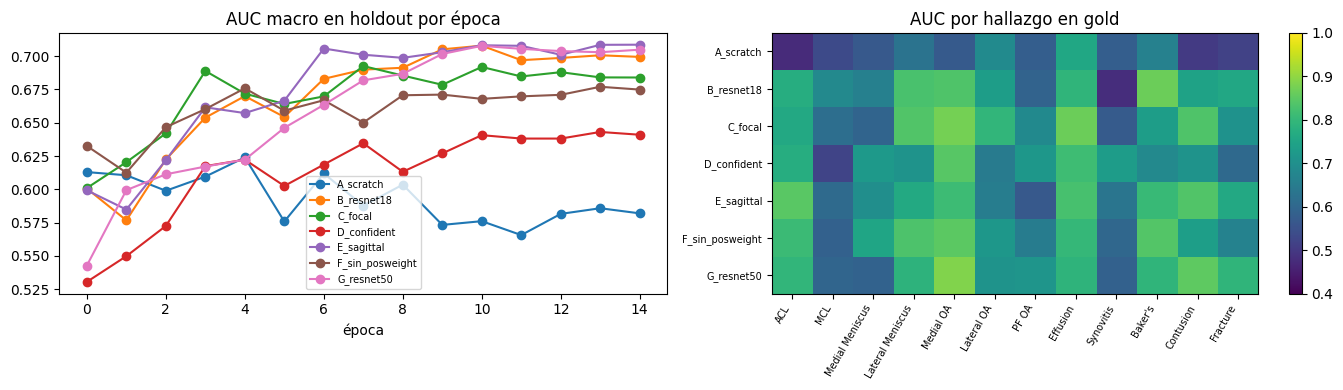

In [9]:
def bootstrap(y, p, p_ref=None, n=1000):
    rng, s = np.random.default_rng(0), []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        v = macro_auc(y[i], p[i]) - (macro_auc(y[i], p_ref[i]) if p_ref is not None else 0)
        if not np.isnan(v):
            s.append(v)
    return np.percentile(s, [2.5, 97.5]) if s else (np.nan, np.nan)


def best_thresholds(y, p):
    th = np.full(12, 0.5)
    for j in range(12):
        if 0 < y[:, j].sum() < len(y):
            cand = np.unique(p[:, j])
            th[j] = cand[int(np.argmax([f1_score(y[:, j], p[:, j] >= t, zero_division=0) for t in cand]))]
    return th


def label_table(name):
    r, rows = RESULTS[name], []
    th = best_thresholds(ho_y, r['p_ho'])
    for j, l in enumerate(LABELS):
        y, p = gold_y[:, j], r['p_gold'][:, j]
        pr, rc, f1, _ = precision_recall_fscore_support(y, p >= th[j], average='binary', zero_division=0)
        rows.append(dict(hallazgo=l, prevalencia_gold=y.mean(),
                         AUC=roc_auc_score(y, p) if 0 < y.sum() < len(y) else np.nan,
                         umbral=th[j], precision=pr, recall=rc, F1=f1))
    return pd.DataFrame(rows).set_index('hallazgo')


if MODE in ('synthetic', 'train'):
    import matplotlib.pyplot as plt
    ref = 'B_resnet18' if 'B_resnet18' in RESULTS else next(iter(RESULTS))
    summary, per_label = [], {}
    for name, r in RESULTS.items():
        auc = macro_auc(gold_y, r['p_gold'])
        lo, hi = bootstrap(gold_y, r['p_gold'])
        d_lo, d_hi = bootstrap(gold_y, r['p_gold'], RESULTS[ref]['p_gold']) if name != ref else (np.nan, np.nan)
        summary.append(dict(experimento=name, AUC_gold=auc, IC95=f'[{lo:.3f}, {hi:.3f}]',
                            delta_vs_ref=auc - macro_auc(gold_y, RESULTS[ref]['p_gold']),
                            IC95_delta=f'[{d_lo:.3f}, {d_hi:.3f}]', AUC_holdout=macro_auc(ho_y, r['p_ho']),
                            mejor_epoca=r['epoch'], minutos=r['minutes']))
        per_label[name] = label_table(name)
    SUMMARY = pd.DataFrame(summary).set_index('experimento')
    AUC_LABEL = pd.DataFrame({n: t.AUC for n, t in per_label.items()}).T
    print(SUMMARY.round(3).to_string())
    print('\nAUC por hallazgo (gold):\n', AUC_LABEL.round(3).to_string())
    cand = SUMMARY.drop(index='A_scratch', errors='ignore')
    best_name = (cand if len(cand) else SUMMARY).AUC_holdout.fillna(0).idxmax()   # elegido sin mirar gold
    print(f'\nmejor modelo por holdout: {best_name}\n', per_label[best_name].round(3).to_string())

    # Variabilidad entre semillas: el IC bootstrap mide el azar de los 58 gold; esto mide el del entrenamiento.
    # delta_vs_ref compara cada semilla con la MISMA semilla de la referencia.
    SEEDS_DF = pd.DataFrame([dict(experimento=n, semilla=s, macro=macro_auc(gold_y, p),
                                  **{l: roc_auc_score(gold_y[:, j], p[:, j]) if 0 < gold_y[:, j].sum() < len(gold_y) else np.nan
                                     for j, l in enumerate(LABELS)})
                             for (n, s), p in SEED_P.items()])
    SEEDS_DF['delta_vs_ref'] = SEEDS_DF.macro - SEEDS_DF.semilla.map(SEEDS_DF[SEEDS_DF.experimento == ref].set_index('semilla').macro)
    SEED_SUMMARY = SEEDS_DF.groupby('experimento', sort=False)[['macro', 'delta_vs_ref']].agg(['mean', 'std', 'min', 'max'])
    print(f'\nAUC macro gold en {SEEDS_DF.semilla.nunique()} semillas:\n', SEED_SUMMARY.round(3).to_string())
    SEEDS_DF.to_csv(f'{WORK}/semillas.csv', index=False)

    rare = PREV.sort_values('train (débil)').index[:4]                # entregable 6: hallazgos más raros
    cols = [c for c in ('B_resnet18', 'C_focal', 'F_sin_posweight') if c in AUC_LABEL.index]
    print('\nhallazgos raros (AUC gold):\n', AUC_LABEL.loc[cols, rare].round(3).to_string())

    SUMMARY.to_csv(f'{WORK}/resumen_experimentos.csv'); AUC_LABEL.to_csv(f'{WORK}/auc_por_hallazgo.csv')
    pd.concat(per_label).to_csv(f'{WORK}/metricas_por_hallazgo.csv'); LABEL_QA.to_csv(f'{WORK}/calidad_etiquetas.csv')
    LANG_QA.to_csv(f'{WORK}/calidad_por_idioma.csv'); PREV.to_csv(f'{WORK}/prevalencia.csv')

    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    for name, r in RESULTS.items():
        ax[0].plot(r['hist'].epoch, r['hist'].auc_holdout, 'o-', label=name)
    ax[0].set_title('AUC macro en holdout por época'); ax[0].set_xlabel('época'); ax[0].legend(fontsize=7)
    im = ax[1].imshow(AUC_LABEL.values.astype(float), vmin=0.4, vmax=1, cmap='viridis', aspect='auto')
    ax[1].set_xticks(range(12)); ax[1].set_xticklabels(LABELS, rotation=60, ha='right', fontsize=7)
    ax[1].set_yticks(range(len(AUC_LABEL))); ax[1].set_yticklabels(AUC_LABEL.index, fontsize=7)
    ax[1].set_title('AUC por hallazgo en gold'); plt.colorbar(im, ax=ax[1])
    plt.tight_layout(); plt.savefig(f'{WORK}/experimentos.png', dpi=150); plt.show()

## 8. Interpretabilidad: Grad-CAM (entregable 5)
Grad-CAM (Selvaraju et al., 2017) sobre la última capa convolucional del mejor modelo: los gradientes del
logit de un hallazgo respecto de los mapas de activación dan un peso por canal; el mapa es ReLU(Σ peso·activación).
Como un estudio tiene muchas ventanas, se muestra la ventana a la que **la consulta de ese hallazgo** prestó más
atención. Para cada hallazgo se toma el estudio gold positivo con mayor probabilidad predicha.
Preguntar en el informe: ¿el mapa de "menisco" cae en los meniscos? ¿el de "derrame" en el receso suprapatelar?

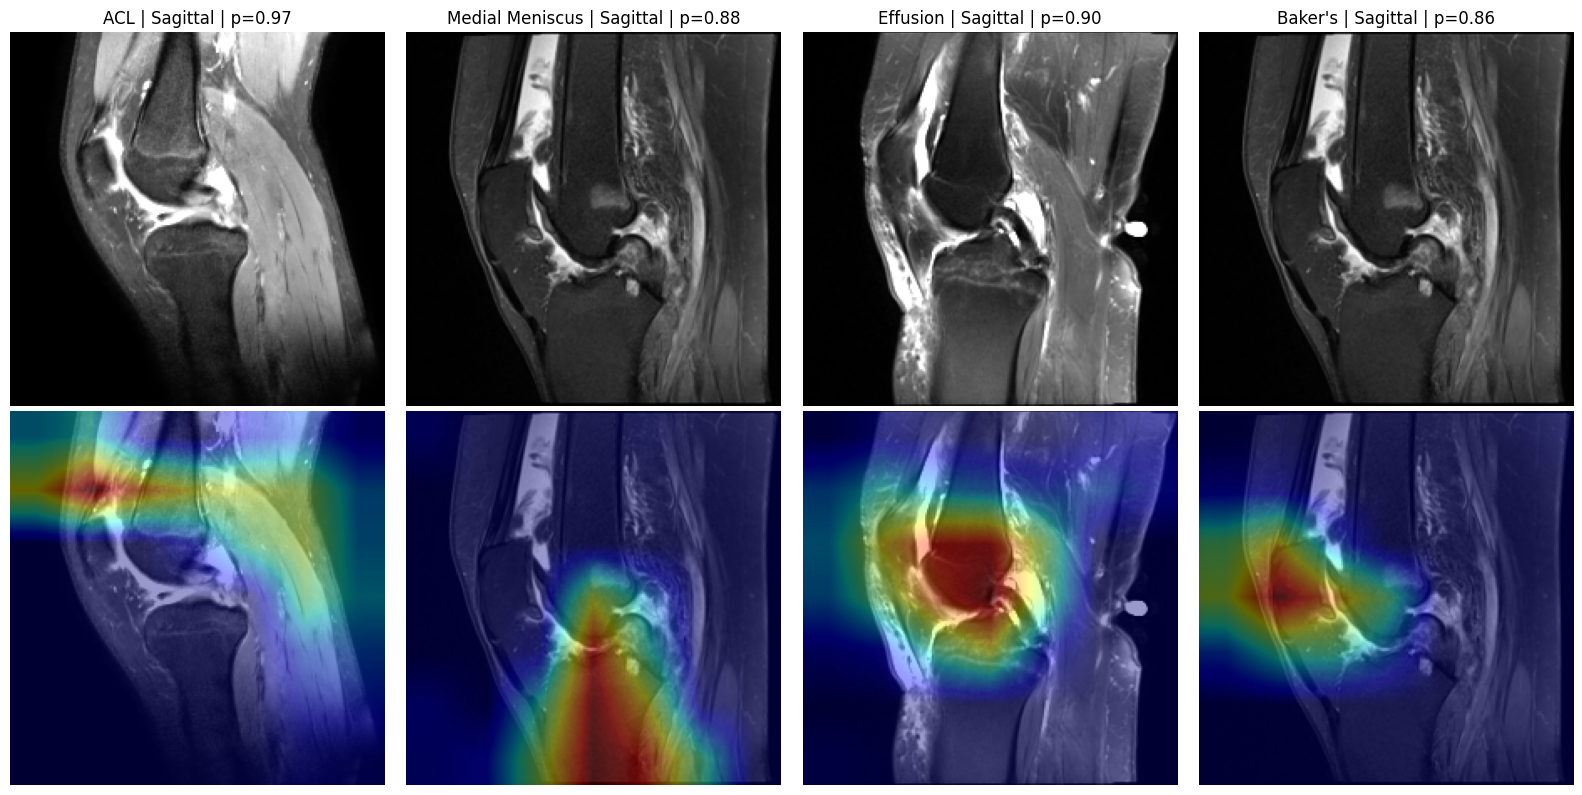

In [10]:
CAM_FINDINGS = ['ACL', 'Medial Meniscus', 'Effusion', 'Baker\'s']


def grad_cam(model, x, pos, slot, keep, j):
    acts = {}
    def hook(m, i, o):
        acts['a'] = o
        o.register_hook(lambda g: acts.__setitem__('g', g))
    h = model._cam[0].register_forward_hook(hook)
    model.eval(); model.zero_grad()
    logit = model(gpu_prep(x, False), pos, slot, keep)[0, j]
    logit.backward(); h.remove()
    n = int(model.last_att[0, j].argmax())                            # ventana más atendida por el hallazgo j
    A, G = acts['a'][n], acts['g'][n]
    cam = F.relu((G.mean((1, 2))[:, None, None] * A).sum(0))
    cam = F.interpolate(cam[None, None], size=x.shape[-2:], mode='bilinear', align_corners=False)[0, 0]
    return n, (cam / (cam.max() + 1e-8)).detach().cpu().numpy(), torch.sigmoid(logit).item()


if MODE in ('synthetic', 'train'):
    ck = torch.load(f'{WORK}/ckpt_{best_name}.pt', map_location=DEVICE)
    model = KneeNet(ck['cfg']['backbone'], pretrained=False, d=ck['cfg']['d_model']).to(DEVICE)
    model.load_state_dict(ck['model'])
    ds = KneeDS(lambda i: (vols[row[gold_ids[i]]], masks[row[gold_ids[i]]]), len(gold_ids), planes=ck['cfg']['planes'])
    fig, axes = plt.subplots(2, len(CAM_FINDINGS), figsize=(4 * len(CAM_FINDINGS), 8))
    for c, f in enumerate(CAM_FINDINGS):
        j = LABELS.index(f)
        cands = np.where(gold_y[:, j] == 1)[0]
        if not len(cands):
            axes[0, c].set_title(f'{f}: sin positivos gold'); continue
        i = cands[np.argmax(RESULTS[best_name]['p_gold'][cands, j])]
        x, pos, slot, keep, _, _ = (t[None].to(DEVICE) if t.dim() else t for t in ds[i])
        n, cam, prob = grad_cam(model, x, pos, slot, keep, j)
        img = x[0, n, 1].float().cpu().numpy()
        assert np.isfinite(cam).all()
        axes[0, c].imshow(img, cmap='gray'); axes[0, c].set_title(f'{f} | {PLANES[int(slot[0, n])]} | p={prob:.2f}')
        axes[1, c].imshow(img, cmap='gray'); axes[1, c].imshow(cam, cmap='jet', alpha=0.4)
        for a in axes[:, c]:
            a.axis('off')
    plt.tight_layout(); plt.savefig(f'{WORK}/gradcam.png', dpi=150); plt.show()
    torch.save(ck, f'{WORK}/kneenet.pt')                              # mejor modelo, para el modo infer

## 9. Inferencia opcional y `submission.csv`
No es requisito del examen. Con internet **apagado**, crea la arquitectura sin descargar pesos y carga
`kneenet.pt` (salida de `knee-train`). Primero escribe un `submission.csv` válido con 0.5.

In [11]:
if MODE in ('synthetic', 'infer'):
    test_df = pd.read_csv(f'{COMP}/test.csv')
    test_series = pd.read_csv(f'{COMP}/test_series.csv')
    sub = pd.DataFrame({'StudyInstanceUID': test_df.StudyInstanceUID})
    sub[LABELS] = 0.5
    sub.to_csv(f'{WORK}/submission.csv', index=False)

    ck = torch.load(f'{WORK if SYN else find_dir("kneenet.pt")}/kneenet.pt', map_location=DEVICE)
    CFG.update({k: ck['cfg'][k] for k in ('img', 'depth', 'd_model')})
    model = KneeNet(ck['cfg']['backbone'], pretrained=False, d=CFG['d_model']).to(DEVICE)
    model.load_state_dict(ck['model'])

    src = DicomStudies('test', test_df.StudyInstanceUID, test_series)
    dl = DataLoader(KneeDS(src.__getitem__, len(src), planes=ck['cfg']['planes']), batch_size=2, num_workers=CFG['workers'])
    t0 = time.time()
    sub[LABELS] = predict(model, dl)
    sub.to_csv(f'{WORK}/submission.csv', index=False)
    print(f'{len(sub)} estudios en {time.time() - t0:.0f}s')
    print(sub.head())

## 10. Verificaciones

In [12]:
if MODE in ('synthetic', 'infer'):
    s = pd.read_csv(f'{WORK}/submission.csv')
    expected = ['StudyInstanceUID'] + LABELS
    assert list(s.columns) == expected, s.columns
    assert list(pd.read_csv(f'{COMP}/sample_submission.csv').columns) == expected
    assert s.StudyInstanceUID.tolist() == test_df.StudyInstanceUID.tolist()
    assert s[LABELS].notna().all().all() and s[LABELS].apply(lambda c: c.between(0, 1)).all().all()
if SYN:
    v = np.load(f'{WORK}/train_vols.npy', mmap_mode='r')
    assert v.shape[1:] == (3, CFG['depth'], CFG['img'], CFG['img']) and v.max() > 0
    assert LABEL_QA.acuerdo.mean() > 0.8, 'el extractor debería acertar en los reportes sintéticos'
    assert set(RESULTS) == set(EXPERIMENTS) and all(np.isfinite(r['p_gold']).all() for r in RESULTS.values())
    assert len(SEEDS_DF) == 2 * len(EXPERIMENTS) and SEEDS_DF.macro.notna().all()
    assert not glob.glob(f'{WORK}/ckpt_*_s[0-9]*.pt'), 'los checkpoints de semillas extra deben borrarse'
    print('OK: pipeline sintético completo')